Data Science Fundamentals Course Work - Kristopher Mann

1. Introduction

In this notebook I will analyse a specific team from the Scottish Premier Football league. With this data I expect to explore trends, notice performance patterns, and apply machine learning techniques such as regression, classification and/or clustering.

This project focuses on analysing Motherwell’s performance during a selected Scottish Premiership season. The overall aim was to explore how different match statistics (such as shots, shots on target, and goals conceded) affect results, and then build simple machine learning models to understand and predict match outcomes.

This project includes:

Exploratory data analysis (EDA),
Feature Engineering,
Regression Analysis,
Classification Model,
Model Evaluation,
Visualisation,
Performance summary.

In [2]:
import numpy as np

In [3]:
import pandas as pd

In [4]:
import matplotlib.pyplot as plt

In [5]:
import sklearn as skl

In [98]:
import seaborn as sns

In [106]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

2. Data Overview

I have imported Libraries that I will believe to be useful in my goal to manipulate data (pandas), numerical calculations (numpy), visually represent data (matplotlib) as well as help with machine learning (scikit-learn).

In [6]:
df = pd.read_csv("data/matches.csv")

C:\Users\kris-\AppData\Local\Temp\ipykernel_13040\1809676358.py:1: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/matches.csv")


I have downloaded a file from Kaggle that contains data on football teams from across Europe ranging from 2000-2024.

The software is going to filter the teams by country, then by league until it achieves the required team.
I will then proceed to have the software find patterns using visual graphs - such as posession to goals, expected Goals per game - this will later help me find information on how to improve and the team is doing correctly.

In [7]:
df['Division'].unique() #this will show an array of divisions from the database file.

array(['F1', 'F2', 'T1', 'D1', 'D2', 'B1', 'E2', 'E1', 'N1', 'P1', 'E0',
       'I2', 'SP2', 'SP1', 'I1', 'E3', 'SC0', 'SC1', 'SC2', 'SC3', 'G1',
       'EC', 'USA', 'SWE', 'NOR', 'IRL', 'BRA', 'ARG', 'MEX', 'JAP',
       'RUS', 'POL', 'DEN', 'ROM', 'AUT', 'SUI', 'FIN', 'CHN'],
      dtype=object)

SC0 is the one needed as this is the Scottish Premier League

In [8]:
scotland_df = df[df['Division'] == 'SC0']

I have filtered it to the Scottish Leagues only.

In [9]:
scotland_df.head() #for checking if the previous line of code has worked!

,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,...,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
5617,SC0,2001-07-28,NaN,Aberdeen,Rangers,1366.48,1622.03,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,0.1186,0.0247,0.8188,0.0099,0.0163,0.0117
5618,SC0,2001-07-28,NaN,Celtic,St Johnstone,1645.14,1346.46,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,0.0113,0.8610,0.0101,0.0225,0.0275,0.0675
5619,SC0,2001-07-28,NaN,Dundee United,Dundee,1329.24,1401.24,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,0.8986,0.0144,0.0100,0.0298,0.0112,0.0360
5620,SC0,2001-07-28,NaN,Dunfermline,Motherwell,1310.34,1347.08,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,0.1051,0.5787,0.0938,0.0100,0.0356,0.1768
5621,SC0,2001-07-28,NaN,Hibernian,Kilmarnock,1448.52,1403.55,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,0.2366,0.1254,0.0099,0.5819,0.0216,0.0246


The software checks the teams listed in the database within the Scottish League.

In [10]:
scotland_df['HomeTeam'].unique()

array(['Aberdeen', 'Celtic', 'Dundee United', 'Dunfermline', 'Hibernian',
       'Livingston', 'Dundee', 'Hearts', 'Kilmarnock', 'Motherwell',
       'Rangers', 'St Johnstone', 'Partick', 'Inverness C', 'Falkirk',
       'St Mirren', 'Gretna', 'Hamilton', 'Ross County'], dtype=object)

The software will fliter the database to search for a team named "Motherwell".

In [11]:
selectedTeam_df = scotland_df[(scotland_df['HomeTeam'] == 'Motherwell') | (scotland_df['AwayTeam'] == 'Motherwell')]

Checking below to see if it has filtered correctly

In [12]:
selectedTeam_df.head()

,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,...,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
5620,SC0,2001-07-28,NaN,Dunfermline,Motherwell,1310.34,1347.08,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,0.1051,0.5787,0.0938,0.0100,0.0356,0.1768
5663,SC0,2001-08-04,NaN,Motherwell,Dundee United,1339.57,1335.89,0.0,0.0,3.0,...,NaN,NaN,NaN,NaN,0.2891,0.0707,0.5391,0.0099,0.0169,0.0744
5785,SC0,2001-08-12,NaN,Motherwell,Kilmarnock,1339.57,1412.04,2.0,3.0,2.0,...,NaN,NaN,NaN,NaN,0.3310,0.1695,0.0537,0.0129,0.0346,0.3984
5859,SC0,2001-08-18,NaN,Aberdeen,Motherwell,1361.02,1344.55,0.0,0.0,2.0,...,NaN,NaN,NaN,NaN,0.2913,0.0259,0.0100,0.0236,0.0200,0.6292
6051,SC0,2001-08-25,NaN,Motherwell,Livingston,1344.55,1304.21,2.0,3.0,2.0,...,NaN,NaN,NaN,NaN,0.4004,0.0124,0.0115,0.0502,0.0251,0.5003


In [13]:
selectedTeam_df['MatchDate'] = pd.to_datetime(selectedTeam_df['MatchDate']) #making sure match date is a date

C:\Users\kris-\AppData\Local\Temp\ipykernel_13040\562444638.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  selectedTeam_df['MatchDate'] = pd.to_datetime(selectedTeam_df['MatchDate']) #making sure match date is a date


In [14]:
selectedSeason_df = selectedTeam_df[(selectedTeam_df['MatchDate'] >= '2024-08-01') & (selectedTeam_df['MatchDate'] <= '2025-05-31')]

In [15]:
selectedSeason_df.head()

,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,...,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
222276,SC0,2024-08-03,15:00:00,Motherwell,Ross County,1303.77,1216.78,3.0,6.0,2.0,...,2.11,-0.5,1.93,1.93,0.3293,0.2860,0.0276,0.2424,0.0975,0.0172
222376,SC0,2024-08-10,15:00:00,Rangers,Motherwell,1618.20,1303.77,5.0,8.0,1.0,...,3.10,-2.0,2.00,1.85,0.0214,0.0151,0.0326,0.0100,0.9065,0.0144
222960,SC0,2024-08-25,15:00:00,Motherwell,Hearts,1291.50,1407.19,1.0,4.0,2.0,...,2.10,0.3,1.73,2.08,0.0508,0.1212,0.0191,0.0594,0.7025,0.0470
223181,SC0,2024-08-31,15:00:00,St Johnstone,Motherwell,1238.60,1291.50,3.0,7.0,4.0,...,1.82,0.3,1.78,2.10,0.3293,0.0346,0.0099,0.5659,0.0217,0.0385
223537,SC0,2024-09-14,15:00:00,Aberdeen,Motherwell,1368.73,1313.54,9.0,13.0,6.0,...,1.98,-0.8,1.90,1.95,0.0111,0.0281,0.9182,0.0099,0.0228,0.0099


In [16]:
selectedSeason_df['MatchDate'].min(), selectedSeason_df['MatchDate'].max() #showing the max and min time frame selected

(Timestamp('2024-08-03 00:00:00'), Timestamp('2025-05-18 00:00:00'))

Now that the software has filtered the database to the selected data it will preceed to use all the techniques that I have covered in data science fundamentals that are relevant to this project.

The software will now analyse Motherwells attacking and defensive performances by checking goals scored and goals conceeded.

In [17]:
selectedSeason_df.columns

Index(['Division', 'MatchDate', 'MatchTime', 'HomeTeam', 'AwayTeam', 'HomeElo',
       'AwayElo', 'Form3Home', 'Form5Home', 'Form3Away', 'Form5Away', 'FTHome',
       'FTAway', 'FTResult', 'HTHome', 'HTAway', 'HTResult', 'HomeShots',
       'AwayShots', 'HomeTarget', 'AwayTarget', 'HomeFouls', 'AwayFouls',
       'HomeCorners', 'AwayCorners', 'HomeYellow', 'AwayYellow', 'HomeRed',
       'AwayRed', 'OddHome', 'OddDraw', 'OddAway', 'MaxHome', 'MaxDraw',
       'MaxAway', 'Over25', 'Under25', 'MaxOver25', 'MaxUnder25', 'HandiSize',
       'HandiHome', 'HandiAway', 'C_LTH', 'C_LTA', 'C_VHD', 'C_VAD', 'C_HTB',
       'C_PHB'],
      dtype='object')

In [18]:
selectedSeason_df = selectedSeason_df.copy() #This is to stop the "settingWithCopyWarning"

In [19]:
selectedSeason_df['is_home'] = selectedSeason_df['HomeTeam'] == 'Motherwell'

I have created a bool to check if something is at home, else it will be flagged as away.

In [65]:
selectedSeason_df['GoalsFor'] = np.where(
    selectedSeason_df['is_home'],
    selectedSeason_df['FTHome'],
    selectedSeason_df['FTAway']
)

In [64]:
selectedSeason_df['GoalsAgainst'] = np.where(
    selectedSeason_df['is_home'],
    selectedSeason_df['FTAway'],
    selectedSeason_df['FTHome']
)

In [63]:
selectedSeason_df['ShotsFor'] = np.where(
    selectedSeason_df['is_home'],
    selectedSeason_df['HomeShots'],
    selectedSeason_df['AwayShots']
)

In [62]:
selectedSeason_df['ShotsOnTargetFor'] = np.where(
    selectedSeason_df['is_home'],
    selectedSeason_df['HomeTarget'],
    selectedSeason_df['AwayTarget']
)

In [24]:
seasonGoalsScored = selectedSeason_df['GoalsFor'].sum() #this is all the goals scored

In [25]:
seasonGoalsAgainst = selectedSeason_df['GoalsAgainst'].sum() #all the goals conceeded

In [26]:
goalDifference = seasonGoalsScored - seasonGoalsAgainst # this is to get a goal difference for the season

In [27]:
totalMatches = len(selectedSeason_df) # this shows the amount of games played within the seaoson

In [28]:
homeGoalsFor = selectedSeason_df.loc[selectedSeason_df['is_home'], 'GoalsFor'].sum()  #filtered for goals scored at home
homeGoalsForSTD = selectedSeason_df.loc[selectedSeason_df['is_home'], 'GoalsFor'].std()  #standard deviation for home goals

In [29]:
awayGoalsFor = selectedSeason_df.loc[~selectedSeason_df['is_home'], 'GoalsFor'].sum() # filtered for goals scored at away games
awayGoalsForSTD = selectedSeason_df.loc[~selectedSeason_df['is_home'], 'GoalsFor'].std()

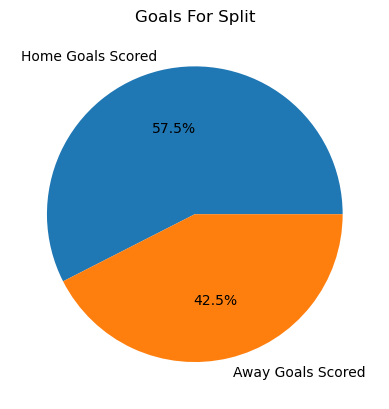

In [30]:
plt.pie(
    [homeGoalsFor, awayGoalsFor],
    labels=['Home Goals Scored', 'Away Goals Scored'],
    autopct='%1.1f%%'
)
plt.title("Goals For Split")
plt.show()

Below is the Goals conceeded!

In [31]:
homeGoalsAgainst = selectedSeason_df.loc[selectedSeason_df['is_home'], 'GoalsAgainst'].sum() #filtering for away goals scored

In [32]:
awayGoalsAgainst = selectedSeason_df.loc[~selectedSeason_df['is_home'], 'GoalsAgainst'].sum() #filtering for away goals conceeded

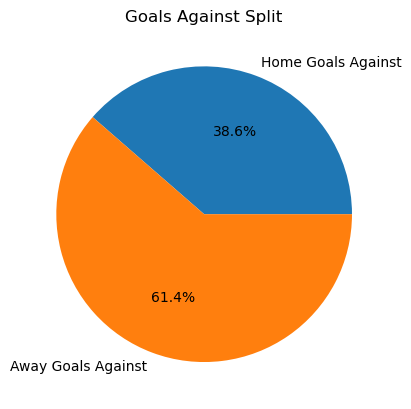

In [33]:
plt.pie(
    [homeGoalsAgainst, awayGoalsAgainst],
    labels=['Home Goals Against', 'Away Goals Against'],
    autopct='%1.1f%%'
)
plt.title("Goals Against Split")
plt.show()

Below is the avg shots / shots on target

In [34]:
#Shots for home and away
shotsHome = selectedSeason_df.loc[selectedSeason_df['is_home'],'ShotsFor'].sum() #this will filter for shots made at home games and add them
shotsAway = selectedSeason_df.loc[~selectedSeason_df['is_home'],'ShotsFor'].sum() #this filters for away games and adds up the shots

#SOT = shots on target
sotHome = selectedSeason_df.loc[selectedSeason_df['is_home'], 'ShotsOnTargetFor'].sum() # adds up all home shots on target
sotAway = selectedSeason_df.loc[~selectedSeason_df['is_home'], 'ShotsOnTargetFor'].sum()# adds up all away shots on target

# checking if games have been won or not
matchesWon = selectedSeason_df[selectedSeason_df['GoalsFor'] > selectedSeason_df['GoalsAgainst']] # this filters games that have more goals for then against to determin the winner
matchesLost = selectedSeason_df[selectedSeason_df['GoalsFor'] < selectedSeason_df['GoalsAgainst']] # filters for loses
matchesDrew = selectedSeason_df[selectedSeason_df['GoalsFor'] == selectedSeason_df['GoalsAgainst']] # filters draws
overallWins = len(matchesWon) #calculate how many wins
overallDraws = len(matchesDrew) # calculate how many draws
overallLosses = len(matchesLost) # calculate loses 
homeWins = matchesWon['is_home'].sum() # check for home win
awayWins = (~matchesWon['is_home']).sum() # check for away wins


Using the software i can display all the information I need onto a text-based kpi. This will help create a summary for the data.

3. EDA

This will show what the data looks like before any modeling!

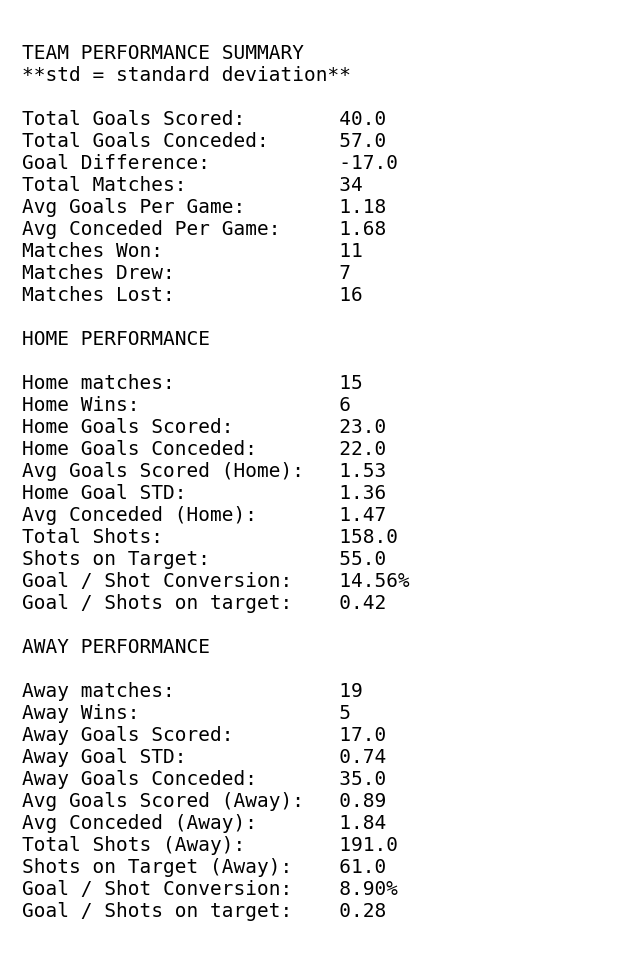

In [35]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.axis('off')  # Hide axes

homeMatches = selectedSeason_df['is_home'].sum()
awayMatches = (~selectedSeason_df['is_home']).sum()

summary_text = f"""
TEAM PERFORMANCE SUMMARY
**std = standard deviation**

Total Goals Scored:        {seasonGoalsScored}
Total Goals Conceded:      {seasonGoalsAgainst}
Goal Difference:           {goalDifference}
Total Matches:             {totalMatches}
Avg Goals Per Game:        {seasonGoalsScored / totalMatches:.2f}
Avg Conceded Per Game:     {seasonGoalsAgainst / totalMatches:.2f}
Matches Won:               {overallWins}
Matches Drew:              {overallDraws}
Matches Lost:              {overallLosses}

HOME PERFORMANCE 

Home matches:              {homeMatches}
Home Wins:                 {homeWins}
Home Goals Scored:         {homeGoalsFor}
Home Goals Conceded:       {homeGoalsAgainst}
Avg Goals Scored (Home):   {homeGoalsFor / homeMatches:.2f}
Home Goal STD:             {homeGoalsForSTD:.2f}
Avg Conceded (Home):       {homeGoalsAgainst / homeMatches:.2f}
Total Shots:               {shotsHome}
Shots on Target:           {sotHome}
Goal / Shot Conversion:    {homeGoalsFor / shotsHome:.2%}
Goal / Shots on target:    {homeGoalsFor/ sotHome:.2f}

AWAY PERFORMANCE 

Away matches:              {awayMatches}
Away Wins:                 {awayWins}
Away Goals Scored:         {awayGoalsFor}
Away Goal STD:             {awayGoalsForSTD:.2f}
Away Goals Conceded:       {awayGoalsAgainst}
Avg Goals Scored (Away):   {awayGoalsFor / awayMatches:.2f}
Avg Conceded (Away):       {awayGoalsAgainst / awayMatches:.2f}
Total Shots (Away):        {shotsAway}
Shots on Target (Away):    {sotAway}
Goal / Shot Conversion:    {awayGoalsFor / shotsAway:.2%}
Goal / Shots on target:    {awayGoalsFor / sotAway:.2f}

"""

ax.text(0.02, 0.98, summary_text, fontsize=14, fontfamily='monospace', va='top');

plt.show()

3. Visualisation

Below the software will create some visualisation for the stats that have been obtained. This data will be displayed in multiple ways, radar graph (specturm), bar charts and scatter plots.

Starting with a radar graph or spectrum. This will show an indepth overview of the teams performans for best to weakest statistic.

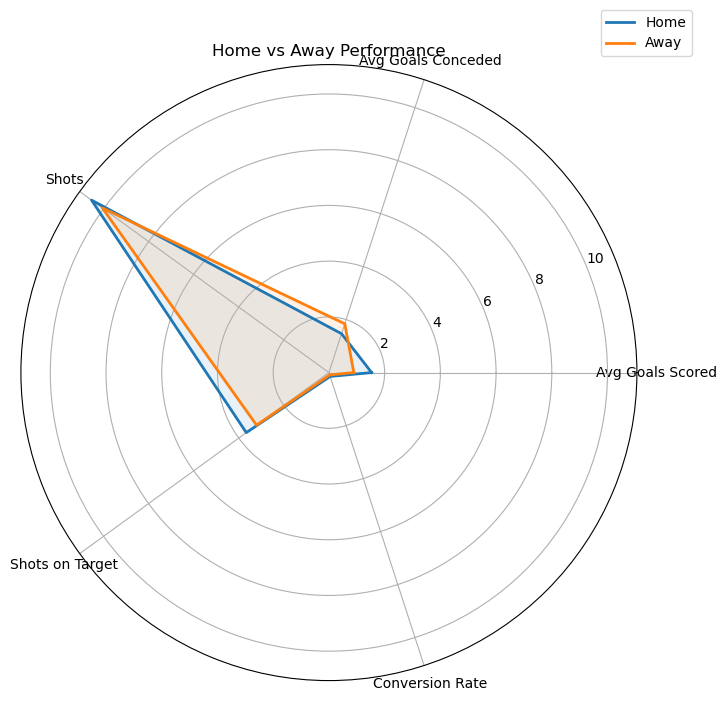

In [48]:
labels = [
    "Avg Goals Scored", 
    "Avg Goals Conceded", 
    "Shots", 
    "Shots on Target", 
    "Conversion Rate"
]

#Using snake casing instead of camel casing on matplotlib cariables so i can keep track
home_stats = [
    homeGoalsFor / homeMatches,
    homeGoalsAgainst / homeMatches,
    shotsHome / homeMatches,
    sotHome / homeMatches,
    homeGoalsFor / shotsHome
]

away_stats = [
    awayGoalsFor / awayMatches,
    awayGoalsAgainst / awayMatches,
    shotsAway / awayMatches,
    sotAway / awayMatches,
    awayGoalsFor / shotsAway
]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
stats_home = np.concatenate((home_stats, [homeStats[0]]))
stats_away = np.concatenate((away_stats, [awayStats[0]]))
angles = np.concatenate((angles, [angles[0]]))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)


ax.plot(angles, stats_home, label="Home", linewidth=2)
ax.fill(angles, stats_home, alpha=0.1)

ax.plot(angles, stats_away, label="Away", linewidth=2)
ax.fill(angles, stats_away, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

ax.set_title("Home vs Away Performance")
ax.legend(loc="upper right", bbox_to_anchor=(1.1, 1.1))

plt.show()

Below is a comparison between goals scored and conceeded, home and away.

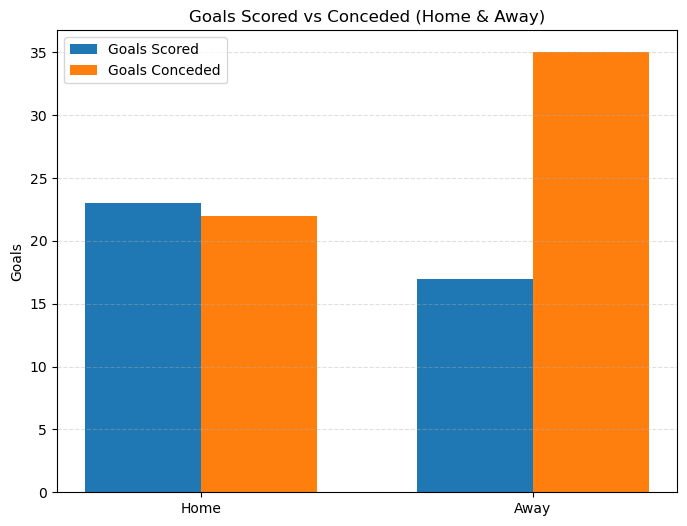

In [49]:
categories = ["Home", "Away"]

goals_for = [homeGoalsFor, awayGoalsFor] #using snake casing for matplotlib variables so i know the difference
goals_against = [homeGoalsAgainst, awayGoalsAgainst]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(8, 6))
plt.bar(x - width/2, goals_for, width, label="Goals Scored")
plt.bar(x + width/2, goals_against, width, label="Goals Conceded")

plt.xticks(x, categories)
plt.ylabel("Goals")
plt.title("Goals Scored vs Conceded (Home & Away)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()

From the bar chart above, we can see that the team scores a similar number of goals at home and away. However, a major factor influencing losses is the number of goals conceded in away games, which is nearly double the amount conceded at home. Since the team scores more goals than they concede at home, this insight suggests that training programs should focus on improving defensive performance in away matches.

Below is a barchart with wins, draws and loses. This allows us to make a comparison by seeing the statistics visually.

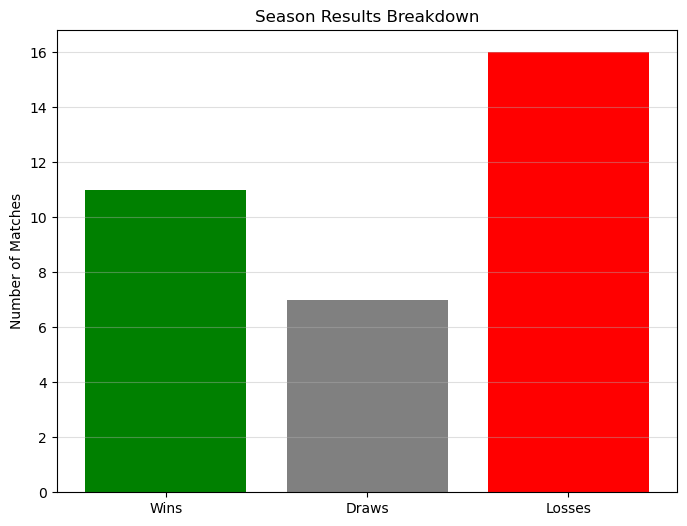

In [53]:
results = ["Wins", "Draws", "Losses"]
values = [overallWins, overallDraws, overallLosses]

plt.figure(figsize=(8, 6))
plt.bar(results, values, color=["green", "grey", "red"])
plt.ylabel("Number of Matches")
plt.title("Season Results Breakdown")
plt.grid(axis="y", linestyle='-', alpha=0.4)
plt.show()

This allows me to come to the conculsion that motherwell tend to Lose majority of their games, and win more than drawing.
The software will now create different graphs with the statistics we have received to determine how we can minimise these loses and turn them to draws or perhaps wins.

I will have the software create different scatter graphs based on similar factors to see if there is a correlation
Below will be scatter graphs for:

      shots for / goals scored
      shots on target / goals scored.

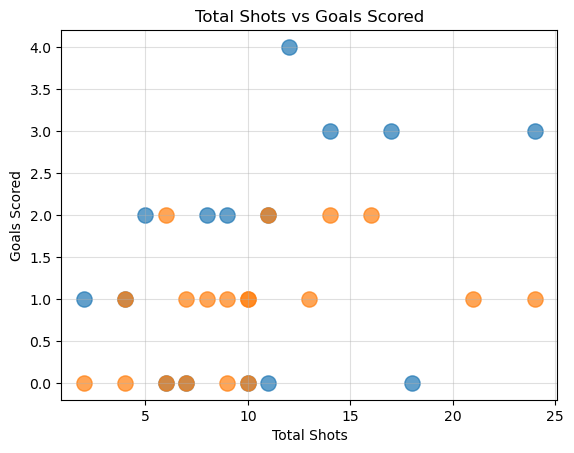

In [71]:
#scatter plot per match
plt.scatter(home_df['ShotsFor'], home_df['GoalsFor'],
            s=120, label='Home', alpha=0.7)
plt.scatter(away_df['ShotsFor'], away_df['GoalsFor'],
            s=120, label='Away', alpha=0.7)

plt.xlabel('Total Shots')
plt.ylabel('Goals Scored')
plt.title('Total Shots vs Goals Scored')
plt.legend
plt.grid(True, linestyle='-', alpha=0.4)
plt.show()

3. Linear Regression

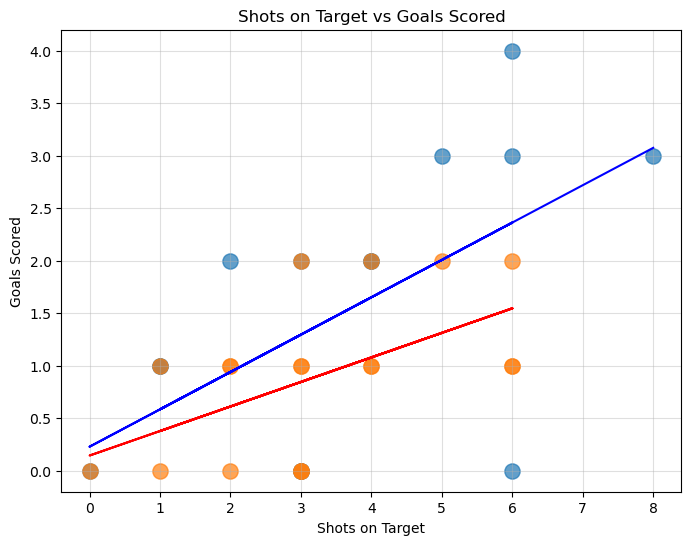

In [83]:
home_df = selectedSeason_df[selectedSeason_df['is_home']] #creating a home and away dataframe so i can plot goals and shots per game.
away_df = selectedSeason_df[~selectedSeason_df['is_home']]
plt.figure(figsize=(8,6))

#scatter plot per match
plt.scatter(home_df['ShotsOnTargetFor'], home_df['GoalsFor'],
            s=120, label='Home', alpha=0.7)
plt.scatter(away_df['ShotsOnTargetFor'], away_df['GoalsFor'],
            s=120, label='Away', alpha=0.7)

# Linear regression for home
m, b = np.polyfit(home_df['ShotsOnTargetFor'], home_df['GoalsFor'], 1)
plt.plot(home_df['ShotsOnTargetFor'], m*home_df['ShotsOnTargetFor'] + b, color='blue', linestyle='-')

# Linear regression for away
m2, b2 = np.polyfit(away_df['ShotsOnTargetFor'], away_df['GoalsFor'], 1)
plt.plot(away_df['ShotsOnTargetFor'], m2*away_df['ShotsOnTargetFor'] + b2, color='red', linestyle='-')

plt.xlabel('Shots on Target')
plt.ylabel('Goals Scored')
plt.title('Shots on Target vs Goals Scored')
plt.legend
plt.grid(True, linestyle='-', alpha=0.4)
plt.show()

Based on these scatter plots, it appears that having more total shots per game does generally lead to more goals, but it is not as strong a determining factor as I initially expected. Most goals are scored when teams take between 5–10 total shots, suggesting that sheer volume of shots isn’t the main driver. In contrast, a higher number of shots on target strongly correlates with more goals scored per game. This insight suggests that training programs should focus on improving shot accuracy and consistency rather than simply increasing the number of shots.

The linear regression lines show that more shots on target generally lead to more goals in both home and away matches. However, for the same number of shots on target, Motherwell scores more goals at home than away, indicating that goal-scoring efficiency is higher in home games.

In [88]:
#Features (X) and target (y)
X = selectedSeason_df[['ShotsFor', 'ShotsOnTargetFor', 'GoalsAgainst', 'is_home']]
y = selectedSeason_df['GoalsFor'] # above stats compared against this to find how effective they are

#Create and fit model
model = LinearRegression()
model.fit(X, y)

#Coefficients for each feature
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_.round(2) #round it to a 2 decimal point
})

feature_importance

,Feature,Coefficient
0,ShotsFor,-0.05
1,ShotsOnTargetFor,0.43
2,GoalsAgainst,0.09
3,is_home,0.50


A simple linear regression model was fitted using total shots, shots on target, goals conceeded and home games to predict how many goals the team scores per match. The resulting coefficient values provide a direct interpretation of the importance and influence of each feature.

The most important predictor was shots on target, with a coefficient of +0.43. This means that each additional shot on target increases the expected number of goals by 0.43 on average. This confirms that shot accuracy, rather than shot frequency, is the key factor to scoring more goals. This finding aligns strongly with the scatter plot analysis, where shots on target showed a clear upward trend.

The home games factor also had a large positive coefficiency of +0.50. This shows that the team typically scores around half a goal more per match when playing at home. This supports the idea of a noticeable home advantage in performance.

Interestingly, ShotsFor had a negative coefficiency of -0.05. This suggests that taking more total shots does not necessarily improve scoring and may reflect situations where the team take low quality shots rather than creating high quality chances.

The coefficiency for GoalsAgainst was slightly positive (+0.09). This may indicate that the teams more chaotic matches involve scoring and conceeding more goals.

4. Classification (Logical Regression and Machine Learning)

In [96]:
selectedSeason_df['Win'] = (selectedSeason_df['GoalsFor'] > selectedSeason_df['GoalsAgainst']).astype(int) #had to recreate a similar variable from above to have it output 1 or 0 for logical regression

X = selectedSeason_df[['ShotsFor', 'ShotsOnTargetFor', 'GoalsAgainst', 'is_home']]
y = selectedSeason_df['Win']

model = LogisticRegression()
model.fit(X, y)

pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.coef_[0].round(2)                                      
})

,Feature,Importance
0,ShotsFor,-0.05
1,ShotsOnTargetFor,0.85
2,GoalsAgainst,-0.70
3,is_home,0.22


Above is a logical regression model. This is used to predict whether the team will win or lose based on performance indicators such as shots, shots on target, goals conceeded, home or away games etc. The resulting coefficients represent how strongly each variable influences the probability of winning.

The most influential factor was shots on target, with a high positive impact of +0.85. This means the increasing number of shots on target raises the likely hood of winning a match. This result supports the linear regression and the scatter plot findings. Shot accuracy is far more important than shot frequency.

Goals Against had a strong negative impact with -0.70, indicating that conceeding goals drastically reduces the chances of winning - this is as expected. This highlights defensive performance as a major factor in match outcomes.

The is_home variable had a positive impact of +0.22, suggesting that the team is more likely to win at home. Although it does not have the same impact as shots on target it still confirms a measurable home advantage.

Finally ShotsFor showed litle to no predictive value with -0.05, indicating that taking more shots does not meaningfully increase chances of winning unless those shots translate to shots on target.

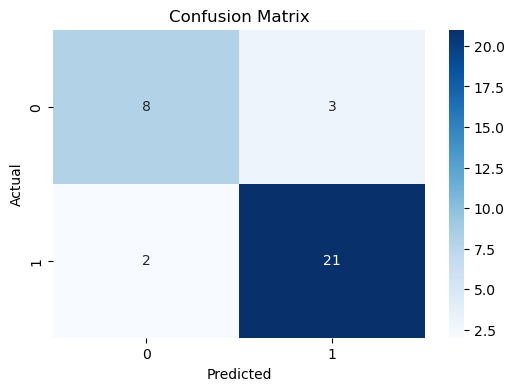

In [129]:
#training the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train) #x_train is data that is tested and then y_train uses the memorised patterns to predict outcomes

# trying to predict win/loss using the logistic model
y_pred = model.predict(X)

#Creating the confusion matrix
cm = confusion_matrix(y, y_pred, labels=[1,0])

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
          
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.title("Confusion Matrix")
plt.show()

From this I can predict the accuracy, precision, and recall of the logical regression model.
For accuracy I will use (TP + TN) / (TP+TN+FP+FN), precision TP / (TP+FP) and recall TP / (TP+FN).

In [124]:
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)  #by default, calculates for label=1
recall = recall_score(y, y_pred)

#rounding it to 2 decimal place
accuracy = round(accuracy, 2)
precision = round(precision, 2)
recall = round(recall, 2)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

print("\nTrain size:", len(X_train))
print("Test size:", len(X_test))


Accuracy: 0.85
Precision: 0.8
Recall: 0.73

Train size: 27
Test size: 7


This logistic regression model correctly predicted most match outcomes, with an overall accuracy of 85%. It preformed well in predicting matches that the team lost with 21 out of 24 games. For actual wins the model correctly predicted 8 out of 10 wins, giving a recall of 73%. Precision for predicted wins was 80% which means most wins predicted as wins were actually wins. This model occasionally underestimated wins with 4 wrongly predicted and overestimated 2 games as false positives.

5. Software Analysis.

System Purpose - This system was created to identify trends and problems that could help Motherwell improve their performance offensive and defensively.
This was done using a number of techniques such as, data cleaning, EDA, visualisation, linear regression and Logical regression.

Input & data processing - the data was inputted from a csv file downloaded from kaggle, it was then filtered to select Motherwell from the SPFL for the 2024/25 season. There were multiple data features created from this, such as: GoalsFor, GoalsAgainst, ShotsFor, ShotsOnTarget, is_home.
From This a data summary was created showing a combination of statistics such as: home games won / lost, goals conceeded, goals scored, shots at home / away, shots on target home / away.

This data was then displayed in a visual format so that it can be easier to analyse, this was done with the use of pie charts, bar charts, radar chart and scatter plot.

From the scatter plot Linear Regression was used to help find a correlation in shots on target / goals scored.

6. Machine Learning pipline
To Train and test this certain data was used, such as:
ShotsFor, ShotsOnTargetFor, GoalsAgainst, is_home. This data had a target variable of "Win" or no win. 80% of the data was used to train the model and the 20% was used to test it.

This was used to train the Logical Regression model that would make predictive guess based on probabilities used in the test data.

To evaluate this we used a confusion matrix to display the outcome and then calculated the accuracy, precision and recall.

7. Future Improvements -
   For furture improvements, more seasons can be evaluated to see yearly progression.
   Additional features can be added such as xG (expected goals), fouls and corners.
   Try to implement more advanced models such as XGBoost or convert to a multiclass classification such as naive bayes.
   Implement clustering for performance grouping.

In [ ]:
8. Conclusion
   This project explored Motherwells performance using real data from previous seasons and applied multiple analytical and machine learning techniques.

   The analysis revealed that: shots on target has a strong relationship with goals scored,

   Home matches showed better attacking and defending performances,

   Away matches involve conceeding a lot more goals and missing more shots,

   overall this project demonstrated how data and machine learning can provide insight into football performance and support the decision making for
   training and tactics.